In [1]:
from qutip import *
import numpy as np
import scipy as sp
import math
import matplotlib.pyplot as plt
from scipy.special import genlaguerre as L
from scipy.optimize import root_scalar as root
import matplotlib.cm as cm

In [2]:
def Omega(n,m,eta):
    return np.abs(np.exp(-eta**2/2.0) * eta**(np.abs(m)) * (math.factorial(n)/math.factorial(n+m))**(np.sign(m)/2.0) \
        * L(n,np.abs(m))(eta**2))             #returns unitless rabi rate of transition n -> n+m given Lamb-Dicke Parameter

def prob(n,nbar):
    return 1.0/(nbar+1)*(nbar/(nbar+1))**n    #returns prob of being in state n given nbar

hbar = sp.constants.hbar
h = sp.constants.h
c = sp.constants.c
e = sp.constants.e
eVtoJ = 1.602176634e-19
amutokg = 1.66053906660e-27
e3 = 642121496772645.10
e2 = 688358979309307.82
omega = 2.0*np.pi*1.0e6 #*650e3
m = 170.936331517*amutokg
#eta = (2.*np.pi*e3/c)*np.sqrt(hbar/(2.*m*omega))
#print(eta)
eta = 0.06882

Ncut = 2001
omegas = np.zeros(Ncut)
#probs = np.zeros(Ncut)
#nbar = 10
for n in range(Ncut):
    omegas[n] = Omega(n,0,eta)
    #probs[n] = prob(n,nbar)

C:\Users\markl\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\special\_orthogonal.py:670: RuntimeWarning: invalid value encountered in scalar divide
  hn = _gam(n + alpha + 1) / _gam(n + 1)
C:\Users\markl\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\special\_orthogonal.py:133: RuntimeWarning: invalid value encountered in multiply
  np.poly1d.__init__(self, poly.coeffs * float(kn))
C:\Users\markl\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\special\_orthogonal.py:119: RuntimeWarning: divide by zero encountered in scalar divide
  equiv_weights = [weights[k] / wfunc(roots[k]) for
C:\Users\markl\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\special\_orthogonal.py:119: RuntimeWarning: invalid value encountered in scalar divide
  equiv_weights = [weights[k] / wfunc(roots[k]) for
C:\Users\markl\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\special\_orthogonal.py:571: RuntimeWarning: overflow encountered

In [3]:
hbar = sp.constants.hbar
h = sp.constants.h
c = sp.constants.c
e = sp.constants.e
eVtoJ = 1.602176634e-19
amutokg = 1.66053906660e-27


def expE(nbar, omega, Ncut):
    expE = 0.0
    for n in range(Ncut):
        expE += prob(n,nbar)*hbar*omega*(0.5+n)
    return expE

def dopAndStark(n): #gives instantaneous doppler and stark shift in angular frequency units
    Ncut = 1201
    omega = 2.0*np.pi*650e3 #Our trap
    Omegarf = 2.0*np.pi*16.026e6 #Our trap
    m = 170.936331517*amutokg
    alpha = 0.888e-40 #J m^2 V^-2 E3 transition (Lange)
    nu0 = 642121496772645.10 #Hz E3 transition (Huntemann)
    return -2.0*np.pi*nu0*hbar*omega*(0.5+n)*(3.0/(m*c**2) + (alpha/(h*nu0))*(3.0*m*Omegarf**2/(2.0*e**2)))
#from Lange eqns 2.11 and 2.12

Ncut = 2001
dopAndStarks = np.zeros(Ncut)
ns = np.linspace(0,Ncut-1,Ncut)
for ii in range(Ncut):
    dopAndStarks[ii] = dopAndStark(ns[ii])

In [4]:
def rhoee(psi, nbar):
    Ncut = np.shape(psi)[0]
    result = 0.
    for n in range(Ncut):
        result += prob(n,nbar)*(abs(psi[n,1]))**2.0
    return result

def rhogg(psi, nbar):
    Ncut = np.shape(psi)[0]
    result = 0.
    for n in range(Ncut):
        result += prob(n,nbar)*(abs(psi[n,0]))**2.0
    return result

def psi(g,e):
    return np.array([g, e])

def groundPsi(Ncut):
    result = np.zeros((Ncut,2),dtype="complex")
    result[:,0] = 1.
    return result

def subPulse(t, Omega0, delta, phi0, phi1):
    Omega = np.sqrt(Omega0**2 + delta**2)
    
    if Omega == 0.0:
        U = np.array([[1.0 , 0.0],
                      [0.0 , 1.0]])
        
    else:
        U = np.array([[np.cos(Omega*t/2.0) -(1.0j*delta/Omega)*np.sin(Omega*t/2.0), (1.0j*Omega0/Omega)*np.sin(Omega*t/2.0)],
                     [(1.0j*Omega0/Omega)*np.sin(Omega*t/2.0) , np.cos(Omega*t/2.0) + (1.0j*delta/Omega)*np.sin(Omega*t/2.0)]])
    
    V1 = np.array([[1.0 , 0.0],
                   [0.0 , np.exp(-1.0j*phi1)]])
    
    V0 = np.array([[1.0 , 0.0],
                   [0.0 , np.exp(1.0j*phi0)]])
    
    return np.exp(1.0j*delta*t/2.0)*V1@U@V0

def pulse(psi, t, Omega0, delta, phi0, phi1):
    Ncut = np.shape(psi)[0]
    result = np.zeros((Ncut,2),dtype="complex")
    if (Omega0==0):
        subpulse = subPulse(t, Omega0, delta, phi0, phi1)
        for n in range(Ncut):
            result[n,:] = subpulse@psi[n,:]
    else:
        for n in range(Ncut):
            result[n,:] = subPulse(t, Omega0*omegas[n], delta, phi0, phi1)@psi[n,:]
    return result

In [54]:
def HRnoheat(deld, psi0, t1, T, t2, del1, del2, Omega0, nbarf, Ncut):
    delp1 = del1
    intState = subPulse(t1, Omega0, delp1, 0.0, 0.0)@psi0
    intStateP = subPulse(0.,0.,0.,0.,np.pi/2.)@intState 
    intStateM = subPulse(0.,0.,0.,0.,-np.pi/2.)@intState
    delp2 = del2
    psiP = subPulse(t2, Omega0, delp2, 0.0, 0.0)@subPulse(T, 0., deld, 0., 0.)@intStateP
    psiM = subPulse(t2, Omega0, delp2, 0.0, 0.0)@subPulse(T, 0., deld, 0., 0.)@intStateM
    return (abs(psiP[1]))**2.0-(abs(psiM[1]))**2.0

In [51]:
def HR(deld, psi0, t1, T, t2, del1, del2, Omega0, nbarf, Ncut):
    nbar0 = 0.
    delp1 = del1
    intState = subPulse(t1, Omega0, delp1, 0.0, 0.0)@psi0
    intStateP = subPulse(0.,0.,0.,0.,np.pi/2.)@intState 
    intStateM = subPulse(0.,0.,0.,0.,-np.pi/2.)@intState
    psiP = np.zeros((Ncut,2),dtype="complex")
    psiM = np.zeros((Ncut,2),dtype="complex")
    for n in range(Ncut):
        phi = (dopAndStarks[n]+dopAndStarks[0])*T/2.0
        delp2 = del2 + dopAndStarks[n] - dopAndStarks[0]
        psiP[n,:] = subPulse(t2, Omega0*omegas[n], delp2, 0.0, 0.0)@subPulse(T, 0., deld, 0., phi)@intStateP
        psiM[n,:] = subPulse(t2, Omega0*omegas[n], delp2, 0.0, 0.0)@subPulse(T, 0., deld, 0., phi)@intStateM
    return rhoee(psiP,nbarf)-rhoee(psiM,nbarf)

def HRJump(deld, psi0, t1, T, t2, del1, del2, Omega0, nbarf, Ncut):
    delp1 = del1
    intState = subPulse(t1, Omega0, delp1, 0.0, 0.0)@psi0
    intStateP = subPulse(0.,0.,0.,0.,np.pi/2.)@intState 
    intStateM = subPulse(0.,0.,0.,0.,-np.pi/2.)@intState
    psiP = np.zeros((Ncut,2),dtype="complex")
    psiM = np.zeros((Ncut,2),dtype="complex")
    for n in range(Ncut):
        phi = (dopAndStarks[n]+dopAndStarks[0])*T/2.0
        delp2 = del2 + dopAndStarks[n] - dopAndStarks[0]
        psiP[n,:] = subPulse(t2/3.0,Omega0*omegas[n],delp2,0.0,0.0)@subPulse(2.0*t2/3.0,-Omega0*omegas[n],delp2,0.0,0.0)@subPulse(T, 0., deld, 0., phi)@intStateP
        psiM[n,:] = subPulse(t2/3.0,Omega0*omegas[n],delp2,0.0,0.0)@subPulse(2.0*t2/3.0,-Omega0*omegas[n],delp2,0.0,0.0)@subPulse(T, 0., deld, 0., phi)@intStateM
    return rhoee(psiP,nbarf)-rhoee(psiM,nbarf)

In [6]:
def shiftCurve(func, t1, T, t2, delp1, delp2, Omega0, nbarfs, Ncut):
    psi0 = psi(1.+0.j,0.+0.j)
    x0 = -2.0
    x1 = 2.0
    guessTol = 5.0
    tol = 1e-6
    pts = np.size(nbarfs)
    shifts = np.zeros(pts)
    for ii in range(pts):
        shifts[ii] = root(func, args=(psi0, t1, T, t2, delp1, delp2, Omega0, nbarfs[ii], Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii])
        x0 = shifts[ii] - guessTol
        x1 = shifts[ii] + guessTol
        print([x0,x1])
    return shifts

# 26.2 + 70 Scan

In [47]:
np.zeros(3)

array([0., 0., 0.])

In [57]:
delpts = 61
delPrime0s = 2.0*np.pi*np.linspace(0,7.5,delpts)
nbarDot = 0

shift0s = np.zeros(delpts)
t1 = 23.9e-3 #t1 = 20.65e-3 ##------------from matching excitation fraction found by experiment, intended to model heating before the sequence begins-----
#t1 = 26.2e-3
T = 150e-3
t2 = 70e-3 #3*24.5e-3 #3*26.3e-3 
Omega0 = np.pi/(2*23.9e-3) #np.pi/(2*23.9e-3)
Ncut = 500
#nbarfs = np.linspace(0,100, nbarfPts)

psi0 = psi(1.+0.j,0.+0.j)
x0 = -2.5
x1 = 2.5
guessTol = 20
tol = 1e-6
nbarf = nbarDot*(22e-3+t1+T+t2)
for ii in range(delpts):
    shift0s[ii] = root(HRnoheat, args=(psi0, t1, T, t2, delPrime0s[ii], delPrime0s[ii], Omega0, 0, 0), bracket=[x0,x1], xtol = tol).root
    print(shifts[ii])
    x0 = shifts[ii] - guessTol
    x1 = shifts[ii] + guessTol
    print([x0,x1])

0.0
[np.float64(-20.0), np.float64(20.0)]
0.009397709557039946
[np.float64(-19.99060229044296), np.float64(20.00939770955704)]
0.018552443050522765
[np.float64(-19.981447556949476), np.float64(20.018552443050524)]
0.02722315509183417
[np.float64(-19.972776844908164), np.float64(20.027223155091836)]
0.035172622307960484
[np.float64(-19.96482737769204), np.float64(20.03517262230796)]
0.04216925752811144
[np.float64(-19.957830742471888), np.float64(20.042169257528112)]
0.04798861425864513
[np.float64(-19.952011385741354), np.float64(20.047988614258646)]
0.052415884036715966
[np.float64(-19.947584115963284), np.float64(20.052415884036716)]
0.05524555372476833
[np.float64(-19.944754446275233), np.float64(20.055245553724767)]
0.056284112789482574
[np.float64(-19.943715887210516), np.float64(20.056284112789484)]
0.05535050830793947
[np.float64(-19.94464949169206), np.float64(20.05535050830794)]
0.052276942916760036
[np.float64(-19.94772305708324), np.float64(20.05227694291676)]
0.046909567440

In [79]:
delpts = 61
delPrimes = 2.0*np.pi*np.linspace(-7.5,7.5,delpts)
nbardotPts = 5
nbarDots = np.array([75, 150, 175, 200, 225])

shifts = np.zeros([delpts, nbardotPts])
t1 = 23.9e-3 #t1 = 20.65e-3 ##------------from matching excitation fraction found by experiment, intended to model heating before the sequence begins-----
#t1 = 26.2e-3
T = 150e-3
t2 = 70e-3 #3*24.5e-3 #3*26.3e-3 
Omega0 = np.pi/(2*23.9e-3) #np.pi/(2*23.9e-3)
Ncut = 500
#nbarfs = np.linspace(0,100, nbarfPts)

psi0 = psi(1.+0.j,0.+0.j)
x0 = -2.5
x1 = 2.5
guessTol = 10.0
tol = 1e-6
for jj in range(nbardotPts):
    nbarf = nbarDots[jj]*(22e-3+t1+T+t2)
    for ii in range(delpts):
        shifts[ii,jj] = root(HR, args=(psi0, t1, T, t2, delPrimes[ii], delPrimes[ii], Omega0, nbarf, Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii,jj])
        x0 = shifts[ii,jj] - guessTol
        x1 = shifts[ii,jj] + guessTol
        print([x0,x1])

2.3794427246923373
[np.float64(-7.620557275307663), np.float64(12.379442724692337)]
2.1206270601132386
[np.float64(-7.879372939886761), np.float64(12.12062706011324)]
1.867122993067545
[np.float64(-8.132877006932455), np.float64(11.867122993067545)]
1.619540478695031
[np.float64(-8.380459521304969), np.float64(11.619540478695031)]
1.3784613935643542
[np.float64(-8.621538606435646), np.float64(11.378461393564354)]
1.1444655969416182
[np.float64(-8.855534403058382), np.float64(11.144465596941618)]
0.9181503350306914
[np.float64(-9.081849664969308), np.float64(10.918150335030692)]
0.7001454957945433
[np.float64(-9.299854504205456), np.float64(10.700145495794544)]
0.4911261851413442
[np.float64(-9.508873814858656), np.float64(10.491126185141344)]
0.2918234582597656
[np.float64(-9.708176541740235), np.float64(10.291823458259765)]
0.10303360869760224
[np.float64(-9.896966391302398), np.float64(10.103033608697602)]
-0.07437391611710477
[np.float64(-10.074373916117105), np.float64(9.9256260838

C:\Users\markl\AppData\Local\Temp\ipykernel_8160\1445714845.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20c')


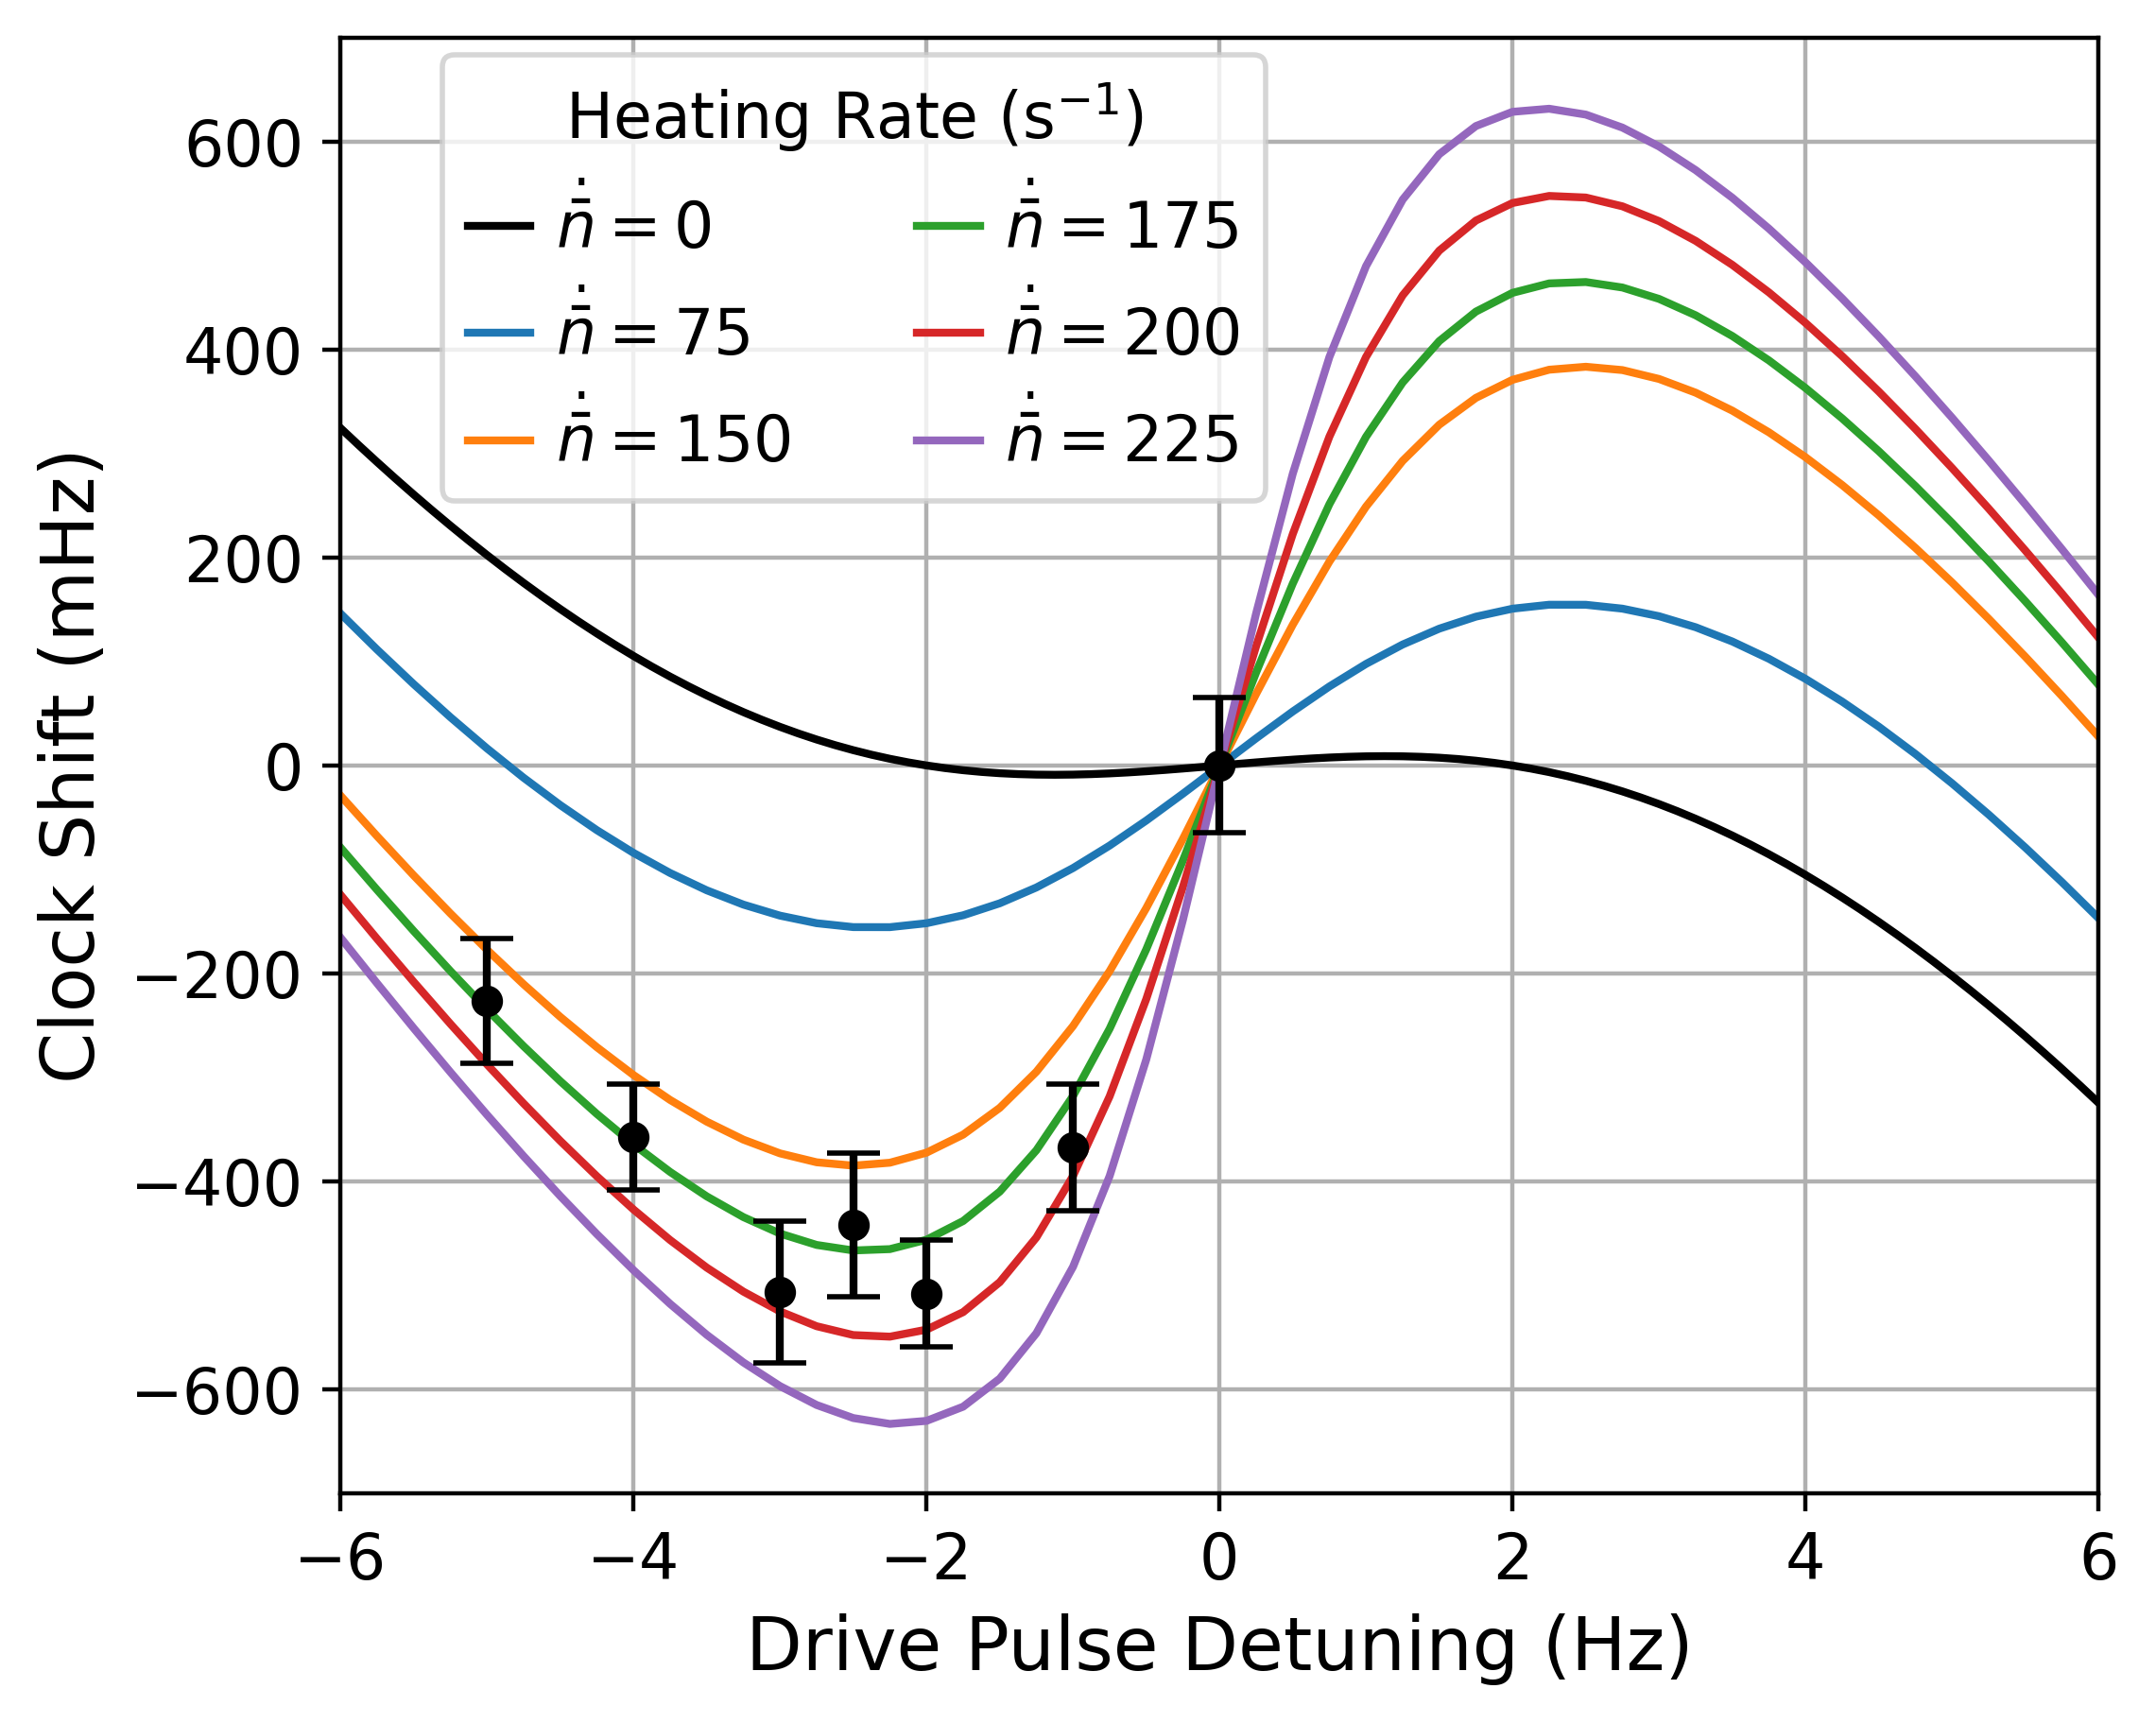

In [108]:
cmap = cm.get_cmap('tab20c')

#colors = ["#1F4E79", "#2A9D8F", "#E9C46A", "#C44536",]
colors = ["#5E60CE", "#00B4D8", "#F4A261", "#E63946",]
plt.figure(figsize=(6,5), dpi=400)
plt.plot(delPrime0s/(2*np.pi), 1e3*shift0s/(2*np.pi), label=r"$\dot{\bar{n}} = 0$", c="black")
plt.plot(-delPrime0s/(2*np.pi), -1e3*shift0s/(2*np.pi),  c="black")

for jj in range(nbardotPts):
    kk=(jj+1)*4-4
    plt.plot(delPrimes/(2*np.pi),1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])))
##----The -2 Hz points are really bad and we don't remember why. ---------
#dels = np.array([-4,-2,-2.5,0,-2,-5,-1,-7,-3])
#shifts = 1e3*np.array([-0.3576,-0.27257,-0.44209,-0.09178,-0.28041,-0.22615,-0.36742,0.26852,-0.50679])
#errs = 1e3*np.array([0.025556,0.039387,0.034439,0.032495,0.030322,0.030003,0.030351,0.033125,0.034106])
##-------Retook the -2Hz point and it looked better:
dels = np.array([-4,-2.5,0,-2,-5,-1,-3])
#Deltas = 1e3*np.array([-0.3576,-0.44209,-0.09178,-0.50783,-0.22615,-0.36742,-0.50679])
Deltas = 1e3*np.array([-0.3576,-0.44209,0.0,-0.50783,-0.22615,-0.36742,-0.50679])

errs = 2*1e3*np.array([0.025556,0.034439,0.032495,0.025474,0.030003,0.030351,0.034106])

plt.errorbar(dels,Deltas,yerr=errs,fmt=".",markersize=10,color="black",capsize=5)
plt.ylim([-700,700])
plt.xlim([-6,6])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend(ncol = 2, title="Heating Rate (s$^{-1})$", title_fontsize=12 ,fontsize=12,loc="upper left", bbox_to_anchor=(0.04, 1.01), handlelength=1, handletextpad=0.4)
#plt.legend(fontsize=14)
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)
plt.xlabel("Drive Pulse Detuning (Hz)", fontsize = 14)
plt.ylabel("Clock Shift (mHz)", fontsize = 14)
#plt.title('HR 1+3 (26.2+70 ms)')
plt.savefig("heatMeasure.pdf", bbox_inches="tight")
plt.show()

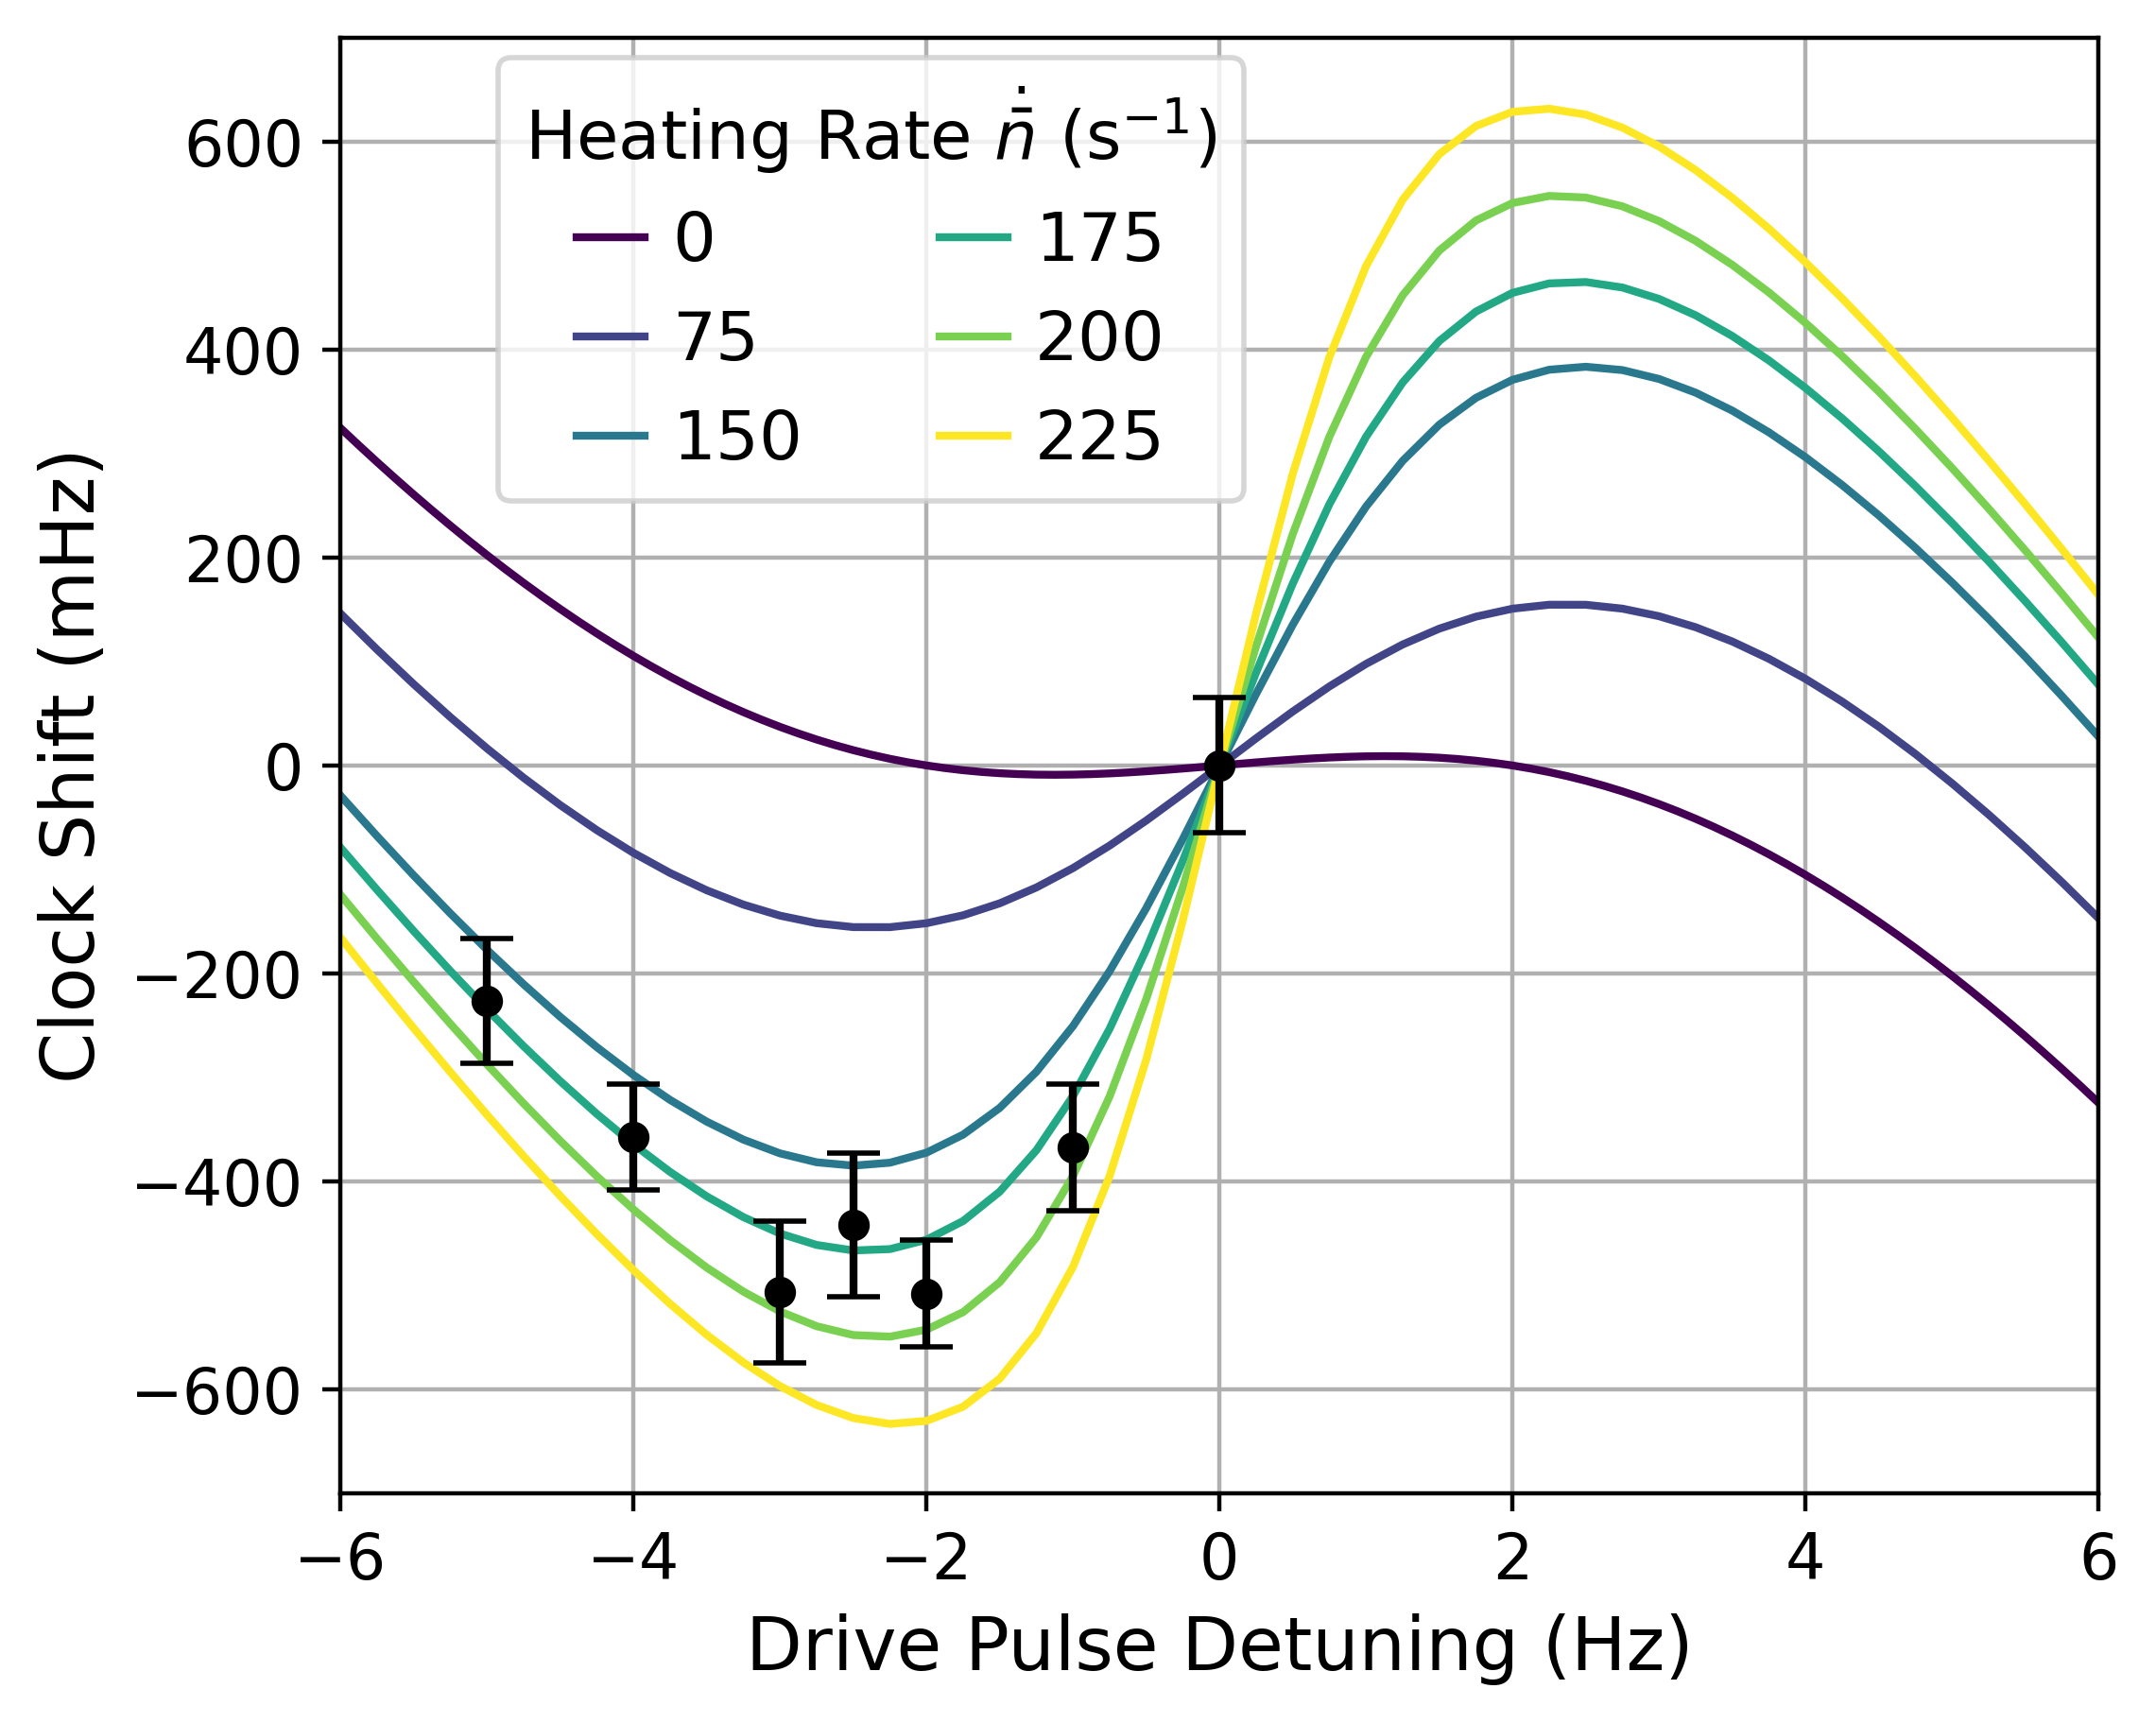

In [125]:
colors = [
    '#1f77b4',  # Blue
    '#d62728',  # Red
    '#2ca02c',  # Green
    '#9467bd',  # Purple
    '#ff7f0e',  # Orange
    '#8c564b',  # Brown
]
colors = [
    '#440154',
    '#414487',
    '#2A788E',
    '#22A884',
    '#7AD151',
    '#FDE725',
]
plt.figure(figsize=(6,5), dpi=400)
plt.plot(delPrime0s/(2*np.pi), 1e3*shift0s/(2*np.pi), label=r"0", c=colors[0])
plt.plot(-delPrime0s/(2*np.pi), -1e3*shift0s/(2*np.pi),  c=colors[0])

for jj in range(nbardotPts):
    kk=(jj+1)*4-4
    plt.plot(delPrimes/(2*np.pi),1e3*shifts[:,jj]/(2*np.pi),label=str(int(nbarDots[jj])),c= colors[jj+1])
##----The -2 Hz points are really bad and we don't remember why. ---------
#dels = np.array([-4,-2,-2.5,0,-2,-5,-1,-7,-3])
#shifts = 1e3*np.array([-0.3576,-0.27257,-0.44209,-0.09178,-0.28041,-0.22615,-0.36742,0.26852,-0.50679])
#errs = 1e3*np.array([0.025556,0.039387,0.034439,0.032495,0.030322,0.030003,0.030351,0.033125,0.034106])
##-------Retook the -2Hz point and it looked better:
dels = np.array([-4,-2.5,0,-2,-5,-1,-3])
#Deltas = 1e3*np.array([-0.3576,-0.44209,-0.09178,-0.50783,-0.22615,-0.36742,-0.50679])
Deltas = 1e3*np.array([-0.3576,-0.44209,0.0,-0.50783,-0.22615,-0.36742,-0.50679])

errs = 2*1e3*np.array([0.025556,0.034439,0.032495,0.025474,0.030003,0.030351,0.034106])

plt.errorbar(dels,Deltas,yerr=errs,fmt=".",markersize=10,color="black",capsize=5)
plt.ylim([-700,700])
plt.xlim([-6,6])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend(ncol = 2, title=r"Heating Rate $\dot{\bar{n}}$ (s$^{-1})$", title_fontsize=13 ,fontsize=13,loc="upper left", bbox_to_anchor=(0.07, 1.01), handlelength=1, handletextpad=0.4)
#plt.legend(fontsize=14)
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)
plt.xlabel("Drive Pulse Detuning (Hz)", fontsize = 14)
plt.ylabel("Clock Shift (mHz)", fontsize = 14)
#plt.title('HR 1+3 (26.2+70 ms)')
plt.savefig("heatMeasure.pdf", bbox_inches="tight")
plt.show()

C:\Users\markl\AppData\Local\Temp\ipykernel_8160\1498423269.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20c')


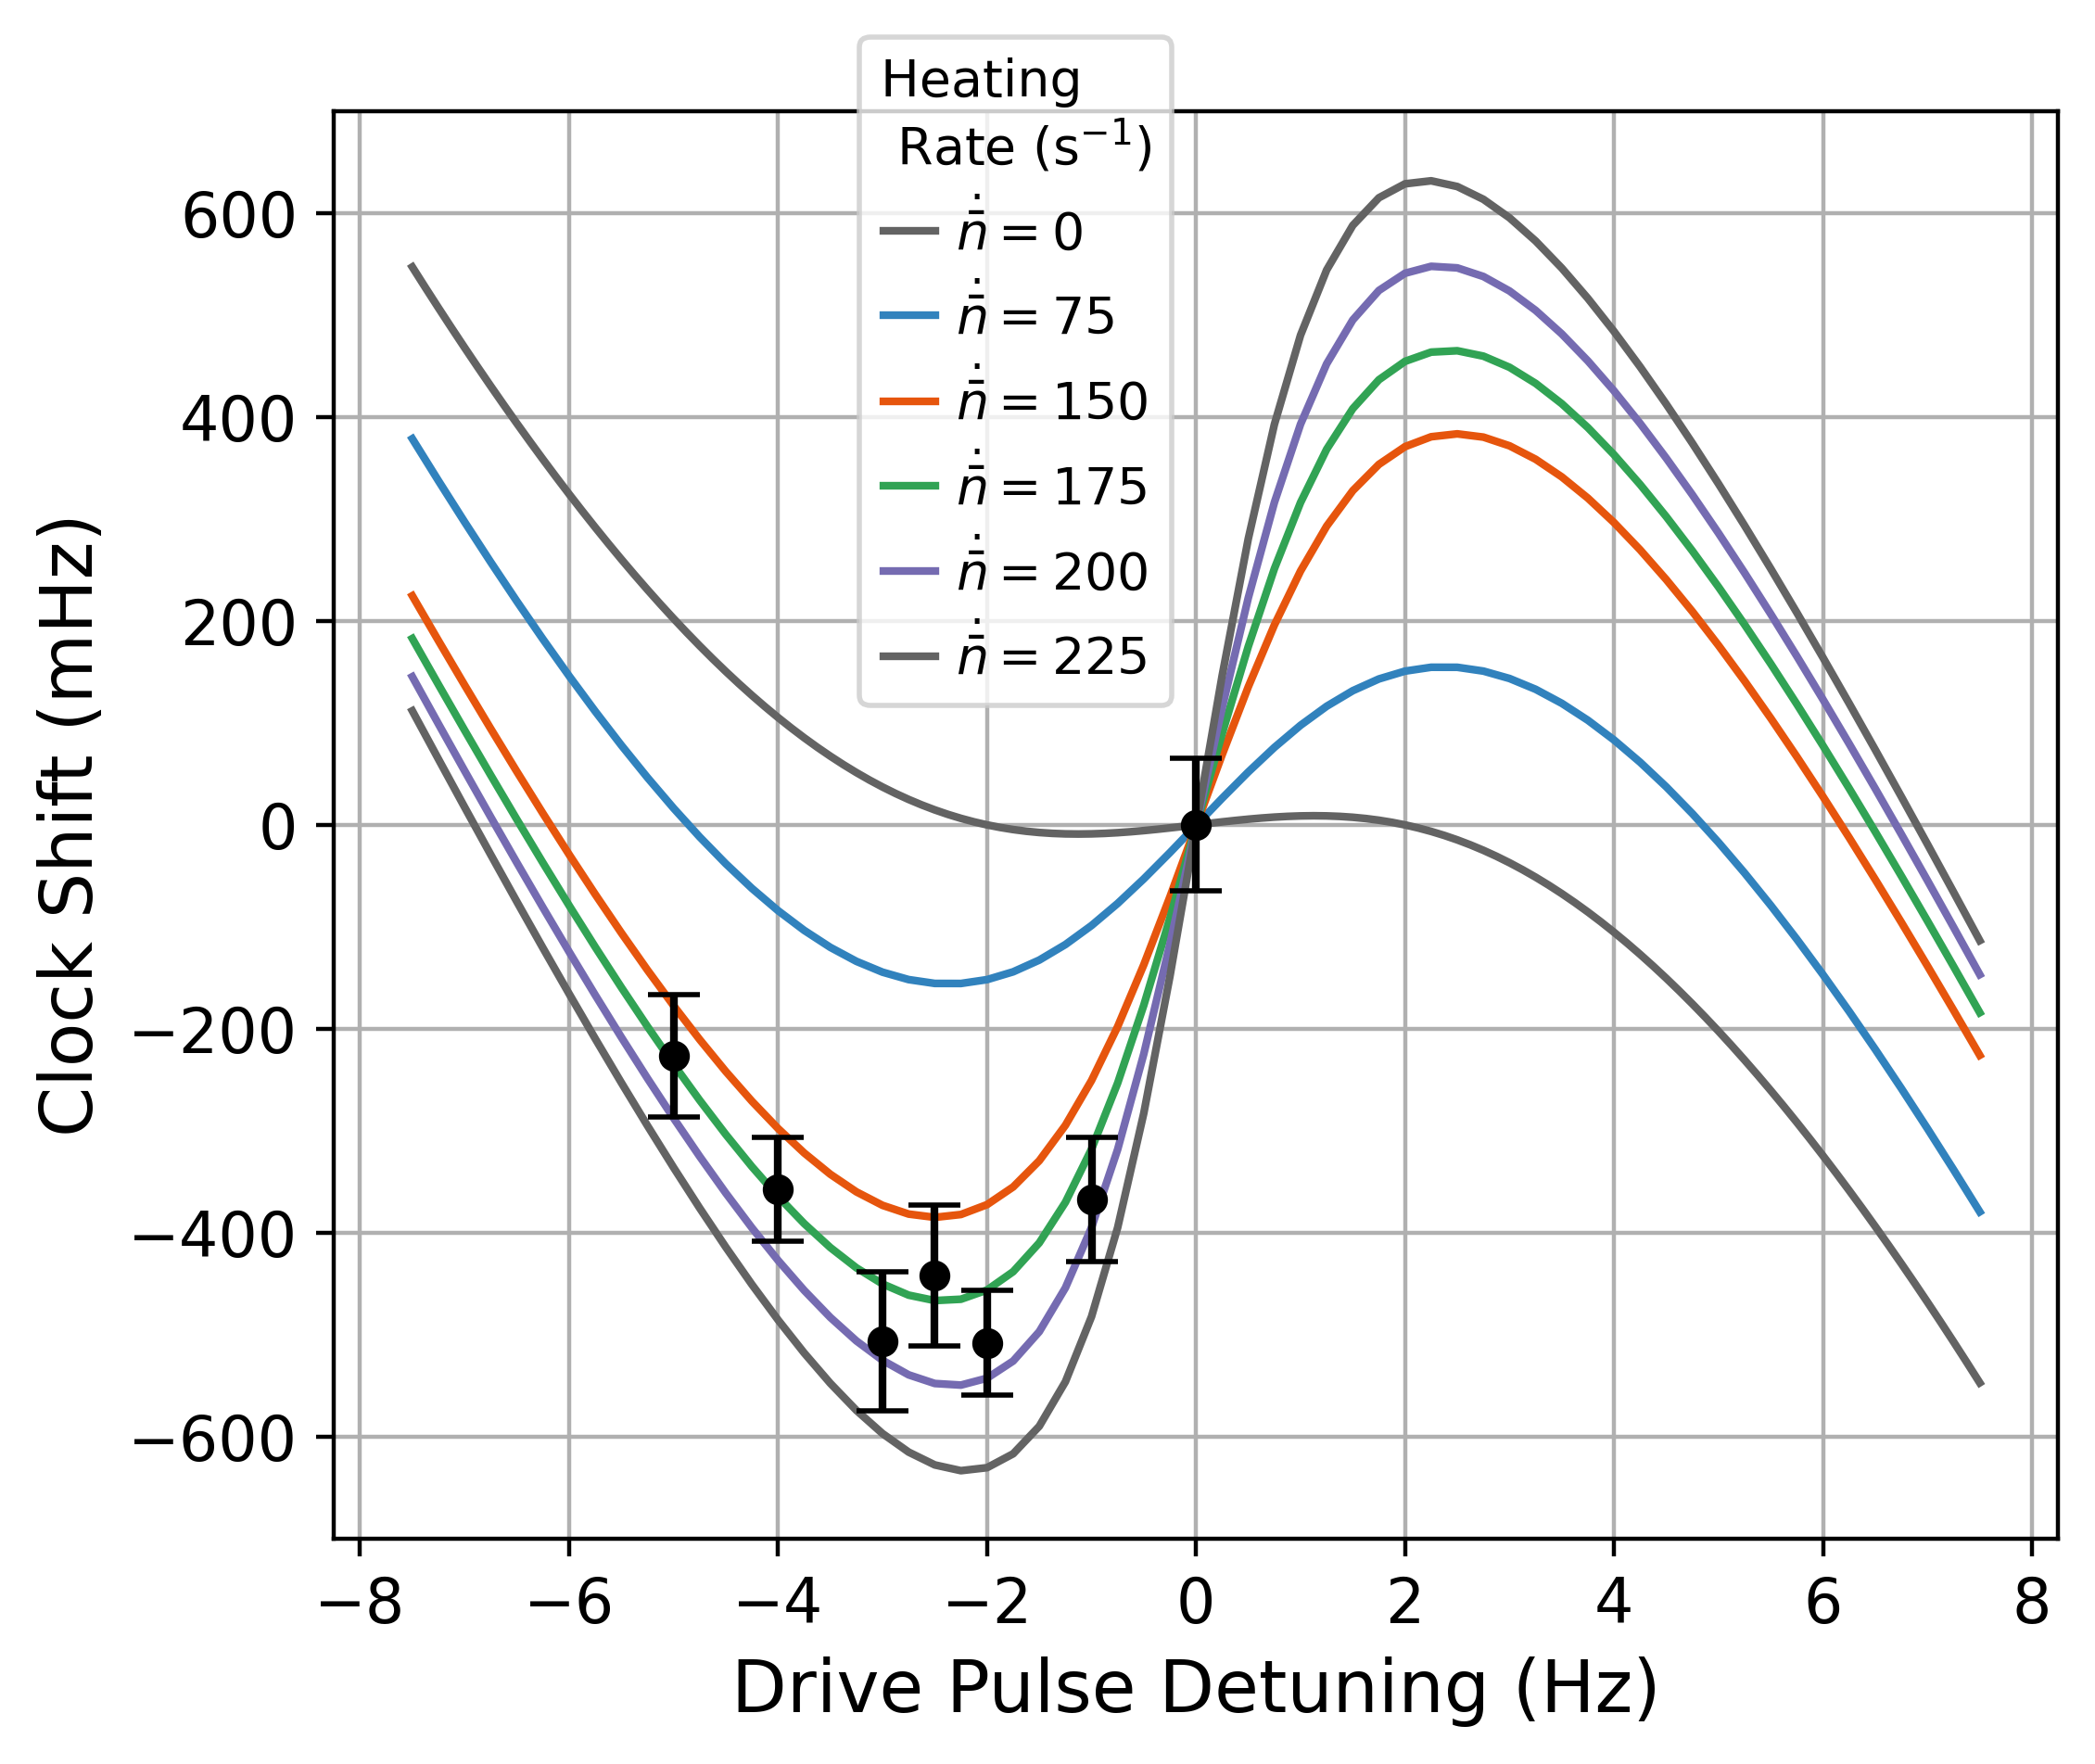

In [92]:
cmap = cm.get_cmap('tab20c')

#colors = ["#1F4E79", "#2A9D8F", "#E9C46A", "#C44536",]
colors = ["#5E60CE", "#00B4D8", "#F4A261", "#E63946",]
plt.figure(figsize=(6,5), dpi=400)
plt.plot(delPrime0s/(2*np.pi), 1e3*shift0s/(2*np.pi), label=r"$\dot{\bar{n}} = 0$", c=cmap((4+1)*4-4))
plt.plot(-delPrime0s/(2*np.pi), -1e3*shift0s/(2*np.pi),  c=cmap((4+1)*4-4))

for jj in range(nbardotPts):
    kk=(jj+1)*4-4
    plt.plot(delPrimes/(2*np.pi),1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])), c=cmap(kk))
##----The -2 Hz points are really bad and we don't remember why. ---------
#dels = np.array([-4,-2,-2.5,0,-2,-5,-1,-7,-3])
#shifts = 1e3*np.array([-0.3576,-0.27257,-0.44209,-0.09178,-0.28041,-0.22615,-0.36742,0.26852,-0.50679])
#errs = 1e3*np.array([0.025556,0.039387,0.034439,0.032495,0.030322,0.030003,0.030351,0.033125,0.034106])
##-------Retook the -2Hz point and it looked better:
dels = np.array([-4,-2.5,0,-2,-5,-1,-3])
#Deltas = 1e3*np.array([-0.3576,-0.44209,-0.09178,-0.50783,-0.22615,-0.36742,-0.50679])
Deltas = 1e3*np.array([-0.3576,-0.44209,0.0,-0.50783,-0.22615,-0.36742,-0.50679])

errs = 2*1e3*np.array([0.025556,0.034439,0.032495,0.025474,0.030003,0.030351,0.034106])

plt.errorbar(dels,Deltas,yerr=errs,fmt=".",markersize=10,color="black",capsize=5)
plt.ylim([-700,700])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend(title="Heating \n Rate (s$^{-1})$", fontsize=10,loc="upper left", bbox_to_anchor=(0.29, 1.07), handlelength=1, handletextpad=0.4)
#plt.legend(fontsize=14)
plt.tick_params(axis='x', labelsize=12)
plt.tick_params(axis='y', labelsize=12)
plt.xlabel("Drive Pulse Detuning (Hz)", fontsize = 14)
plt.ylabel("Clock Shift (mHz)", fontsize = 14)
#plt.title('HR 1+3 (26.2+70 ms)')
plt.savefig("heatMeasure.pdf", bbox_inches="tight")
plt.show()

# 23 + 78 Scan

In [48]:
delpts = 21
delPrimes = 2.0*np.pi*np.linspace(-7.5,7.5,delpts)
nbardotPts = 5
nbarDots = np.linspace(150,250,nbardotPts)

shifts = np.zeros([delpts, nbardotPts])
t1 = 23.9e-3 #t1 = 20.65e-3 ##------------from matching excitation fraction found by experiment, intended to model heating before the sequence begins-----
#t1 = 26.2e-3
T = 150e-3
t2 = 78e-3 #3*24.5e-3 #3*26.3e-3 
Omega0 = np.pi/(2*23.9e-3) #np.pi/(2*23.9e-3)
Ncut = 500
#nbarfs = np.linspace(0,100, nbarfPts)

psi0 = psi(1.+0.j,0.+0.j)
x0 = -2.5
x1 = 2.5
guessTol = 10.0
tol = 1e-6
for jj in range(nbardotPts):
    nbarf = nbarDots[jj]*(22e-3+t1+T+t2)
    for ii in range(delpts):
        shifts[ii,jj] = root(HR, args=(psi0, t1, T, t2, delPrimes[ii], delPrimes[ii], Omega0, nbarf, Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii,jj])
        x0 = shifts[ii,jj] - guessTol
        x1 = shifts[ii,jj] + guessTol
        print([x0,x1])

2.072042508048804
[np.float64(-7.9279574919511955), np.float64(12.072042508048805)]
1.4354602796789713
[np.float64(-8.56453972032103), np.float64(11.43546027967897)]
0.7456872747923282
[np.float64(-9.254312725207672), np.float64(10.745687274792328)]
0.08773330866278276
[np.float64(-9.912266691337217), np.float64(10.087733308662783)]
-0.49297006537257415
[np.float64(-10.492970065372575), np.float64(9.507029934627425)]
-0.9562632499298873
[np.float64(-10.956263249929886), np.float64(9.043736750070114)]
-1.2559642061720055
[np.float64(-11.255964206172006), np.float64(8.744035793827994)]
-1.3373013939308604
[np.float64(-11.337301393930861), np.float64(8.662698606069139)]
-1.1477615615746048
[np.float64(-11.147761561574605), np.float64(8.852238438425395)]
-0.6748437885716252
[np.float64(-10.674843788571625), np.float64(9.325156211428375)]
-0.0059600682143767895
[np.float64(-10.005960068214376), np.float64(9.994039931785624)]
0.6631869690993734
[np.float64(-9.336813030900627), np.float64(10.

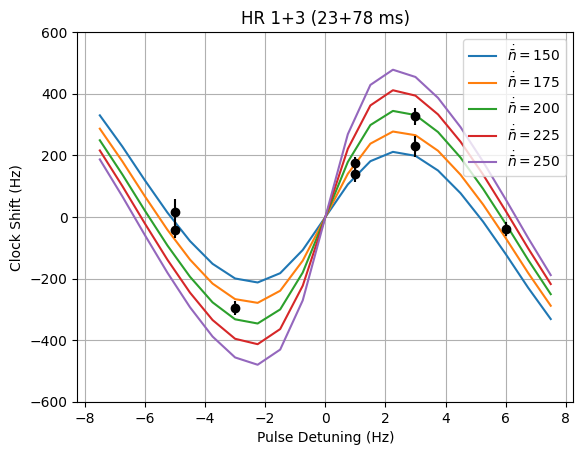

In [49]:
for jj in range(nbardotPts):
    plt.plot(delPrimes/(2*np.pi),1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])))

dels = np.array([-5,6,1,1,-5,3,3,-3])
Deltas = 1e3*np.array([-0.041932,-0.038091,0.13825,0.17493,0.015781,0.32683,0.22976,-0.29608])
errs = 1e3*np.array([0.025082,0.022232,0.025779,0.018623,0.04254,0.028385,0.034408,0.021598])
plt.errorbar(dels,Deltas,yerr=errs,fmt="o",color="black")
plt.ylim([-600,600])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend()
plt.xlabel("Pulse Detuning (Hz)")
plt.ylabel("Clock Shift (Hz)")
plt.title('HR 1+3 (23+78 ms)')
plt.show()

# 79 + 32.5 Scan

In [50]:
delpts = 21
delPrimes = 2.0*np.pi*np.linspace(-7.5,7.5,delpts)
nbardotPts = 5
nbarDots = np.linspace(150,250,nbardotPts)

shifts = np.zeros([delpts, nbardotPts])
Omega0 = np.pi/(2*23.9e-3)
t1 = 3.1*23.9e-3 #t1 = 20.65e-3 ##------------from matching excitation fraction found by experiment, intended to model heating before the sequence begins-----
#t1 = 26.2e-3
T = 150e-3
t2 = 32.5e-3 #3*24.5e-3 #3*26.3e-3 
 #np.pi/(2*23.9e-3)
Ncut = 500
#nbarfs = np.linspace(0,100, nbarfPts)

psi0 = psi(1.+0.j,0.+0.j)

guessTol = 10.0
tol = 1e-6
for jj in range(nbardotPts):
    x0 = -10
    x1 = 10
    nbarf = nbarDots[jj]*(22e-3+t1+T+t2)
    for ii in range(delpts):
        shifts[ii,jj] = root(HR, args=(psi0, t1, T, t2, delPrimes[ii], delPrimes[ii], Omega0, nbarf, Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii,jj])
        x0 = shifts[ii,jj] - guessTol
        x1 = shifts[ii,jj] + guessTol
        print([x0,x1])

6.194597532842973
[np.float64(-3.805402467157027), np.float64(16.194597532842973)]
5.258405087339649
[np.float64(-4.741594912660351), np.float64(15.25840508733965)]
4.382745893363908
[np.float64(-5.617254106636092), np.float64(14.382745893363907)]
3.5718495864413637
[np.float64(-6.428150413558637), np.float64(13.571849586441363)]
2.83151974495251
[np.float64(-7.1684802550474895), np.float64(12.83151974495251)]
2.1682543334816398
[np.float64(-7.83174566651836), np.float64(12.16825433348164)]
1.5875215969997485
[np.float64(-8.412478403000252), np.float64(11.587521596999748)]
1.0909830592717198
[np.float64(-8.90901694072828), np.float64(11.09098305927172)]
0.6729171677899884
[np.float64(-9.327082832210012), np.float64(10.672917167789988)]
0.31705221592350896
[np.float64(-9.682947784076491), np.float64(10.317052215923509)]
-0.004024952920173442
[np.float64(-10.004024952920174), np.float64(9.995975047079826)]
-0.32509984098189265
[np.float64(-10.325099840981892), np.float64(9.67490015901810

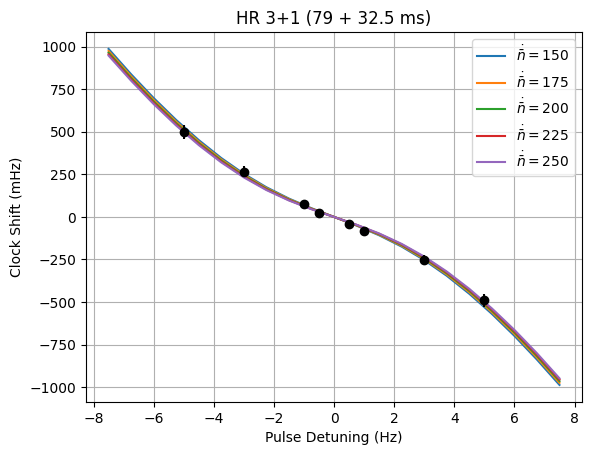

In [51]:
for jj in range(nbardotPts):
    plt.plot(delPrimes/(2*np.pi),1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])))
dels = np.array([0.5,-0.5,1,-1,3,-3,5,-5])
Deltas = 1e3*np.array([-0.041714,0.022276,-0.082444,0.07698,-0.25322,0.2649,-0.4906,0.49846])
errs = 1e3*np.array([0.019617,0.02024,0.024063,0.023242,0.031101,0.031085,0.040151,0.042882])
plt.errorbar(dels,Deltas,yerr=errs,fmt="o",color="black")
#plt.ylim([-600,600])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend()
plt.xlabel("Pulse Detuning (Hz)")
plt.ylabel("Clock Shift (mHz)")
plt.title('HR 3+1 (79 + 32.5 ms)')
plt.show()

# 79 + 22 Scan

In [52]:
delpts = 21
delPrimes = 2.0*np.pi*np.linspace(-7.5,7.5,delpts)
nbardotPts = 5
nbarDots = np.linspace(150,250,nbardotPts)

shifts = np.zeros([delpts, nbardotPts])
Omega0 = np.pi/(2*23.9e-3)
t1 = 3.1*23.9e-3 #t1 = 20.65e-3 ##------------from matching excitation fraction found by experiment, intended to model heating before the sequence begins-----
#t1 = 26.2e-3
T = 150e-3
t2 = 22e-3 #3*24.5e-3 #3*26.3e-3 
Ncut = 500
#nbarfs = np.linspace(0,100, nbarfPts)

psi0 = psi(1.+0.j,0.+0.j)

guessTol = 10.0
tol = 1e-6
for jj in range(nbardotPts):
    x0 = -10
    x1 = 10
    nbarf = nbarDots[jj]*(22e-3+t1+T+t2)
    for ii in range(delpts):
        shifts[ii,jj] = root(HR, args=(psi0, t1, T, t2, delPrimes[ii], delPrimes[ii], Omega0, nbarf, Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii,jj])
        x0 = shifts[ii,jj] - guessTol
        x1 = shifts[ii,jj] + guessTol
        print([x0,x1])

3.374624147935415
[np.float64(-6.625375852064585), np.float64(13.374624147935414)]
2.6605463100995337
[np.float64(-7.339453689900466), np.float64(12.660546310099534)]
2.0220065937164953
[np.float64(-7.977993406283504), np.float64(12.022006593716496)]
1.4633955294461352
[np.float64(-8.536604470553865), np.float64(11.463395529446135)]
0.9902786257045769
[np.float64(-9.009721374295424), np.float64(10.990278625704576)]
0.6084488392374585
[np.float64(-9.39155116076254), np.float64(10.60844883923746)]
0.32215294061611793
[np.float64(-9.677847059383883), np.float64(10.322152940616117)]
0.13129549918644204
[np.float64(-9.868704500813559), np.float64(10.131295499186441)]
0.027884488011299474
[np.float64(-9.9721155119887), np.float64(10.0278844880113)]
-0.007066533225676552
[np.float64(-10.007066533225677), np.float64(9.992933466774323)]
-0.004013939745294527
[np.float64(-10.004013939745295), np.float64(9.995986060254705)]
-0.0009609890667433526
[np.float64(-10.000960989066744), np.float64(9.999

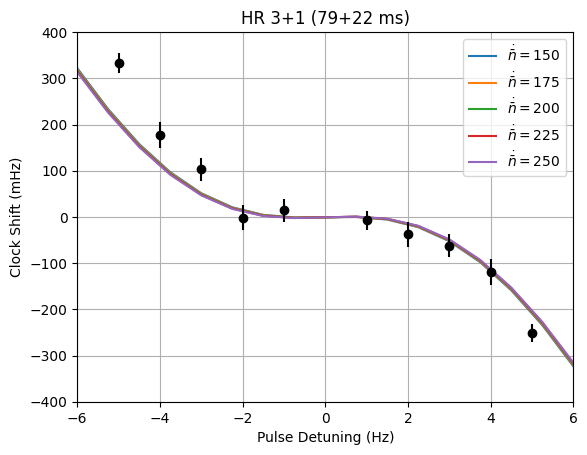

In [53]:
for jj in range(nbardotPts):
    plt.plot(delPrimes/(2*np.pi),1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])))
dels = np.array([-1,-2,4,-4,2,-5,1,5,3,-3])
Deltas = 1e3*np.array([0.013949,-0.0015612,-0.11948,0.17795,-0.037755,0.33335,-0.0074449,-0.25107,-0.062208,0.10306])
errs = 1e3*np.array([0.02573,0.026427,0.02733,0.028355,0.027225,0.021866,0.020577,0.020271,0.024606,0.025098])
plt.errorbar(dels,Deltas,yerr=errs,fmt="o",color="black")
plt.ylim([-400,400])
plt.xlim([-6,6])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend()
plt.xlabel("Pulse Detuning (Hz)")
plt.ylabel("Clock Shift (mHz)")
plt.title('HR 3+1 (79+22 ms)')
plt.show()

# Second Pulse Time Scan

In [42]:
t2pts = 21
delPrime = 3*2*np.pi
t2s = np.linspace(12e-3,36e-3,t2pts)
nbardotPts = 5
nbarDots = np.linspace(150,250,nbardotPts)

shifts = np.zeros([t2pts, nbardotPts])
#t1 = 20.65e-3 ##------------from matching excitation fraction found by experiment, intended to model heating before the sequence begins-----
t1 = 3.1*23.9e-3
T = 150e-3
Omega0 = np.pi/(2*23.9e-3)
Ncut = 500

psi0 = psi(1.+0.j,0.+0.j)

guessTol = 10.0
tol = 1e-6
for jj in range(nbardotPts):
    x0 = -10
    x1 = 10
    for ii in range(t2pts):
        nbarf = nbarDots[jj]*(22e-3+t1+T+t2s[ii])
        shifts[ii,jj] = root(HR, args=(psi0, t1, T, t2s[ii], delPrime, delPrime, Omega0, nbarf, Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii,jj])
        x0 = shifts[ii,jj] - guessTol
        x1 = shifts[ii,jj] + guessTol
        print([x0,x1])

0.4764394936312507
[np.float64(-9.52356050636875), np.float64(10.47643949363125)]
0.3903050335605783
[np.float64(-9.609694966439422), np.float64(10.390305033560578)]
0.30183129207552756
[np.float64(-9.698168707924472), np.float64(10.301831292075528)]
0.21072291258690534
[np.float64(-9.789277087413094), np.float64(10.210722912586906)]
0.1166589221665655
[np.float64(-9.883341077833434), np.float64(10.116658922166566)]
0.01928874754877598
[np.float64(-9.980711252451224), np.float64(10.019288747548776)]
-0.08177243617105572
[np.float64(-10.081772436171056), np.float64(9.918227563828944)]
-0.18694886018075035
[np.float64(-10.18694886018075), np.float64(9.81305113981925)]
-0.2967101163640621
[np.float64(-10.296710116364062), np.float64(9.703289883635938)]
-0.4115779991978649
[np.float64(-10.411577999197865), np.float64(9.588422000802135)]
-0.5321343747725591
[np.float64(-10.532134374772559), np.float64(9.467865625227441)]
-0.6590302300008889
[np.float64(-10.659030230000889), np.float64(9.340

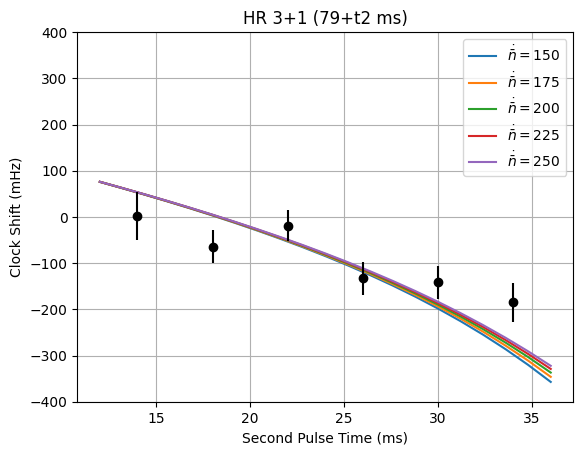

In [43]:
for jj in range(nbardotPts):
    plt.plot(1e3*t2s,1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])))
t2sData = np.array([34,18,14,22,26,30])
Deltas = 1e3*np.array([-0.18485,-0.06489,0.0017499,-0.019373,-0.13326,-0.14092])
errs = 1e3*np.array([0.041616,0.035924,0.052198,0.033585,0.035912,0.035675])
plt.errorbar(t2sData,Deltas,yerr=errs,fmt="o",color="black")
plt.ylim([-400,400])
#plt.xlim([-6,6])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend()
plt.xlabel("Second Pulse Time (ms)")
plt.ylabel("Clock Shift (mHz)")
plt.title('HR 3+1 (79+t2 ms)')
plt.show()

# Dark Time Scan

In [54]:
Tpts = 21
delPrime = -4*2*np.pi
Ts = np.linspace(25e-3,200e-3,Tpts)
nbardotPts = 5
nbarDots = np.linspace(150,250,nbardotPts)

shifts = np.zeros([t2pts, nbardotPts])
t1 = 23.9e-3
t2 = 80e-3
Omega0 = np.pi/(2*23.9e-3)
Ncut = 500
nbardot = 150

psi0 = psi(1.+0.j,0.+0.j)

guessTol = 10.0
tol = 1e-6
for jj in range(nbardotPts):
    x0 = -10
    x1 = 10
    for ii in range(Tpts):
        nbarf = nbarDots[jj]*(22e-3+t1+Ts[ii]+t2)
        shifts[ii,jj] = root(HR, args=(psi0, t1, Ts[ii], t2, delPrime, delPrime, Omega0, nbarf, Ncut), bracket=[x0,x1], xtol = tol).root
        print(shifts[ii,jj])
        x0 = shifts[ii,jj] - guessTol
        x1 = shifts[ii,jj] + guessTol
        print([x0,x1])

3.0777388122595846
[np.float64(-6.922261187740416), np.float64(13.077738812259584)]
1.9163116833121103
[np.float64(-8.08368831668789), np.float64(11.91631168331211)]
1.2320962109385776
[np.float64(-8.767903789061423), np.float64(11.232096210938577)]
0.7810216241478691
[np.float64(-9.218978375852132), np.float64(10.781021624147868)]
0.46137370647289977
[np.float64(-9.5386262935271), np.float64(10.4613737064729)]
0.2232041913607289
[np.float64(-9.776795808639271), np.float64(10.223204191360729)]
0.039107998377719305
[np.float64(-9.96089200162228), np.float64(10.03910799837772)]
-0.10721171686196375
[np.float64(-10.107211716861963), np.float64(9.892788283138037)]
-0.22605913656705906
[np.float64(-10.22605913656706), np.float64(9.77394086343294)]
-0.32427268295700357
[np.float64(-10.324272682957004), np.float64(9.675727317042996)]
-0.4065726324226542
[np.float64(-10.406572632422654), np.float64(9.593427367577346)]
-0.4763251653398542
[np.float64(-10.476325165339855), np.float64(9.523674834

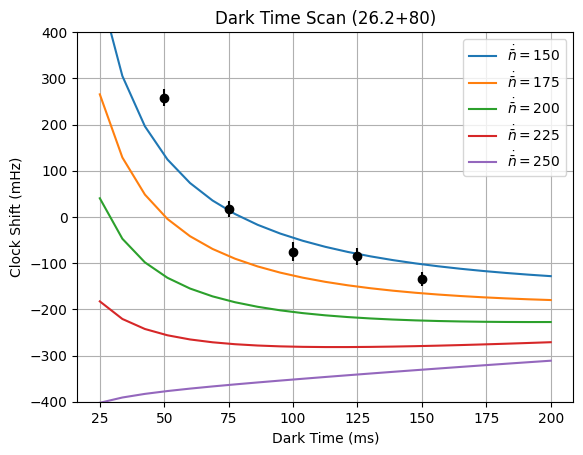

In [55]:
for jj in range(nbardotPts):
    plt.plot(1e3*Ts,1e3*shifts[:,jj]/(2*np.pi),label=r"$\dot{\bar{n}} = $"+str(int(nbarDots[jj])))
TsData = np.array([125,75,100,50,150])
Deltas = 1e3*np.array([-0.084879,0.017144,-0.075009,0.25843,-0.13533])
errs = 1e3*np.array([0.018678,0.017635,0.020245,0.019245,0.01508])
plt.errorbar(TsData,Deltas,yerr=errs,fmt="o",color="black")
plt.ylim([-400,400])
#plt.xlim([-6,6])
#plt.xticks(np.linspace(-6,6,13))
plt.grid()
plt.legend()
plt.xlabel("Dark Time (ms)")
plt.ylabel("Clock Shift (mHz)")
plt.title('Dark Time Scan (26.2+80)')
plt.show()

In [131]:
10e6/2**36

0.00014551915228366852